In [1]:
pip install numpy pandas


Note: you may need to restart the kernel to use updated packages.


In [1]:
import numpy as np
import pandas as pd

df_2019=pd.read_csv("df_2019.csv")
df_2020=pd.read_csv("df_2020.csv")

# Compare column names for each of the files
print("Columns for Q1 2019:\n", df_2019.columns)
print("\nColumns for Q1 2020:\n", df_2020.columns)




Columns for Q1 2019:
 Index(['trip_id', 'start_time', 'end_time', 'bikeid', 'tripduration',
       'from_station_id', 'from_station_name', 'to_station_id',
       'to_station_name', 'usertype', 'gender', 'birthyear'],
      dtype='str')

Columns for Q1 2020:
 Index(['ride_id', 'rideable_type', 'started_at', 'ended_at',
       'start_station_name', 'start_station_id', 'end_station_name',
       'end_station_id', 'start_lat', 'start_lng', 'end_lat', 'end_lng',
       'member_casual'],
      dtype='str')


## Renaming columns to make them Consistent


In [3]:
df_2019=df_2019.rename(columns={
    'trip_id' : 'ride_id',
    'bikeid': 'rideable_type',
    'start_time': 'started_at',
    'end_time': 'ended_at',
    'from_station_name': 'start_station_name',
    'from_station_id': 'start_station_id',
    'to_station_name': 'end_station_name',
    'to_station_id': 'end_station_id',
    'usertype': 'member_casual'   
})

In [4]:
# Inspect the data frames and look for incongruities
print("\nQ1 2019 Data Info:")
df_2019.info()
print("\nQ1 2020 Data Info:")
df_2020.info()



Q1 2019 Data Info:
<class 'pandas.DataFrame'>
RangeIndex: 365069 entries, 0 to 365068
Data columns (total 12 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   ride_id             365069 non-null  int64  
 1   started_at          365069 non-null  str    
 2   ended_at            365069 non-null  str    
 3   rideable_type       365069 non-null  int64  
 4   tripduration        365069 non-null  str    
 5   start_station_id    365069 non-null  int64  
 6   start_station_name  365069 non-null  str    
 7   end_station_id      365069 non-null  int64  
 8   end_station_name    365069 non-null  str    
 9   member_casual       365069 non-null  str    
 10  gender              345358 non-null  str    
 11  birthyear           347046 non-null  float64
dtypes: float64(1), int64(4), str(7)
memory usage: 33.4 MB

Q1 2020 Data Info:
<class 'pandas.DataFrame'>
RangeIndex: 426887 entries, 0 to 426886
Data columns (total 13 columns):
 

In [5]:
# Convert ride_id and rideable_type to string so that they can stack correctly
df_2019['ride_id'] = df_2019['ride_id'].astype(str)
df_2019['rideable_type'] = df_2019['rideable_type'].astype(str)

print("\nQ1 2019 Data Info:")
df_2019.info()
print("\nQ1 2020 Data Info:")
df_2020.info()




Q1 2019 Data Info:
<class 'pandas.DataFrame'>
RangeIndex: 365069 entries, 0 to 365068
Data columns (total 12 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   ride_id             365069 non-null  str    
 1   started_at          365069 non-null  str    
 2   ended_at            365069 non-null  str    
 3   rideable_type       365069 non-null  str    
 4   tripduration        365069 non-null  str    
 5   start_station_id    365069 non-null  int64  
 6   start_station_name  365069 non-null  str    
 7   end_station_id      365069 non-null  int64  
 8   end_station_name    365069 non-null  str    
 9   member_casual       365069 non-null  str    
 10  gender              345358 non-null  str    
 11  birthyear           347046 non-null  float64
dtypes: float64(1), int64(2), str(9)
memory usage: 33.4 MB

Q1 2020 Data Info:
<class 'pandas.DataFrame'>
RangeIndex: 426887 entries, 0 to 426886
Data columns (total 13 columns):
 

In [6]:
# Stack individual quarter's data frames into one big data frame
all_trips = pd.concat([df_2019, df_2020], ignore_index=True)



In [7]:
# Remove lat, long, birthyear, and gender fields as this data was dropped beginning in 2020
# The 'errors="ignore"' argument prevents an error if a column is not found
all_trips = all_trips.drop(columns=['start_lat', 'start_lng', 'end_lat', 'end_lng', 'birthyear', 'gender', 'tripduration'], errors='ignore')


## Cleaning Process


In [8]:
#List of Columns
print("\nList of column names:\n", all_trips.columns)
#Num Of rows
print("\nHow many rows are in data frame?", len(all_trips))
#Num of rows and columns
print("\nDimensions of the data frame:", all_trips.shape)
#first 6 rows
print("\nSee the first 6 rows of data frame:\n", all_trips.head())
#Data types the dataframe contains
print("\nSee list of columns and data types:\n")
all_trips.info()



List of column names:
 Index(['ride_id', 'started_at', 'ended_at', 'rideable_type',
       'start_station_id', 'start_station_name', 'end_station_id',
       'end_station_name', 'member_casual'],
      dtype='str')

How many rows are in data frame? 791956

Dimensions of the data frame: (791956, 9)

See the first 6 rows of data frame:
     ride_id          started_at            ended_at rideable_type  \
0  21742443  2019-01-01 0:04:37  2019-01-01 0:11:07          2167   
1  21742444  2019-01-01 0:08:13  2019-01-01 0:15:34          4386   
2  21742445  2019-01-01 0:13:23  2019-01-01 0:27:12          1524   
3  21742446  2019-01-01 0:13:45  2019-01-01 0:43:28           252   
4  21742447  2019-01-01 0:14:52  2019-01-01 0:20:56          1170   

   start_station_id                   start_station_name  end_station_id  \
0               199               Wabash Ave & Grand Ave            84.0   
1                44               State St & Randolph St           624.0   
2                15

In [9]:
# How many values Membar_casual
all_trips['member_casual'].value_counts()

member_casual
member        378407
Subscriber    341906
casual         48480
Customer       23163
Name: count, dtype: int64

In [10]:
#Replace subscriber > member and customer > casual
all_trips['member_casual']=all_trips['member_casual'].replace({
    'Subscriber': 'member',
    'Customer': 'casual'
})

#Checking if the values of subscriber and customer have been changed 
all_trips['member_casual'].value_counts()

member_casual
member    720313
casual     71643
Name: count, dtype: int64

In [11]:
# Convert 'started_at' and 'ended_at' to datetime objects
all_trips['started_at'] = pd.to_datetime(all_trips['started_at'])
all_trips['ended_at'] = pd.to_datetime(all_trips['ended_at'])


In [12]:
# Add columns that list the date, month, day, and year of each ride
all_trips['date']=all_trips['started_at'].dt.date
all_trips['month']=all_trips['started_at'].dt.month
all_trips['day']=all_trips['started_at'].dt.day
all_trips['year']=all_trips['started_at'].dt.year
# Get the day name
all_trips['day_of_week']=all_trips['started_at'].dt.day_name()

In [14]:
#Ride length in seconds
all_trips['ride_length']=(all_trips['ended_at']-all_trips['started_at']).dt.total_seconds()

In [15]:
#Columns structure inspection
print("\nData Types after adding date columns and ride_length:\n")
all_trips.info()


Data Types after adding date columns and ride_length:

<class 'pandas.DataFrame'>
RangeIndex: 791956 entries, 0 to 791955
Data columns (total 15 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   ride_id             791956 non-null  str           
 1   started_at          791956 non-null  datetime64[us]
 2   ended_at            791956 non-null  datetime64[us]
 3   rideable_type       791956 non-null  str           
 4   start_station_id    791956 non-null  int64         
 5   start_station_name  791956 non-null  str           
 6   end_station_id      791955 non-null  float64       
 7   end_station_name    791955 non-null  str           
 8   member_casual       791956 non-null  str           
 9   date                791956 non-null  object        
 10  month               791956 non-null  int32         
 11  day                 791956 non-null  int32         
 12  year                791956 non-null  int3

In [16]:
#Removing bad data where ride_length was negative and bikes that were taken out of docksfor quality checks
all_trips_v2 = all_trips[(all_trips['start_station_name'] != "HQ QR") & (all_trips['ride_length'] >= 0)].copy()


## DESCRIPTIVE ANALYSIS


In [17]:
# Descriptive analysis on ride_length (all figures in seconds)
print("\nDescriptive statistics for ride_length:\n", all_trips_v2['ride_length'].describe())

# Compare members and casual users
print("\nRide length statistics grouped by member_casual:\n", all_trips_v2.groupby('member_casual')['ride_length'].agg(['mean', 'median', 'max', 'min']))

# See the average ride time by each day for members vs casual users
print("\nAverage ride length by member type and day of the week:\n", all_trips_v2.groupby(['member_casual', 'day_of_week'])['ride_length'].mean())

# Order the days of the week for correct sorting for analysis
days_order = ["Sunday", "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday"]
all_trips_v2['day_of_week'] = pd.Categorical(all_trips_v2['day_of_week'], categories=days_order, ordered=True)

# Now, run the aggregation again to see the sorted result
print("\nAverage ride length (sorted by day of week):\n", all_trips_v2.groupby(['member_casual', 'day_of_week'])['ride_length'].mean())

# Analyze ridership data by type and weekday
summary_stats = all_trips_v2.groupby(['member_casual', 'day_of_week']).agg(
    number_of_rides=('ride_id', 'count'),
    average_duration=('ride_length', 'mean')
).reset_index()

print("\nSummary of rides and duration by rider type and weekday:\n", summary_stats)



Descriptive statistics for ride_length:
 count    7.881890e+05
mean     1.189459e+03
std      3.329191e+04
min      1.000000e+00
25%      3.310000e+02
50%      5.390000e+02
75%      9.120000e+02
max      1.063202e+07
Name: ride_length, dtype: float64

Ride length statistics grouped by member_casual:
                       mean  median         max  min
member_casual                                      
casual         5372.783874  1393.0  10632022.0  2.0
member          795.252339   508.0   6096428.0  1.0

Average ride length by member type and day of the week:
 member_casual  day_of_week
casual         Friday         6090.737302
               Monday         4752.050438
               Saturday       4950.770801
               Sunday         5061.304364
               Thursday       8451.666853
               Tuesday        4561.803857
               Wednesday      4480.372432
member         Friday          796.733789
               Monday          822.311202
               Saturday   

In [18]:

summary_stats = all_trips_v2.groupby(['member_casual','day_of_week']).agg(
    # The number of rides by rider type and weekday
    number_of_rides=('ride_id', 'count'),
    # The average ride duration by rider type and weekday 
    average_duration=('ride_length', 'mean')
).reset_index()
print("\nSummary of rides and duration by rider type and weekday:\n", summary_stats)




Summary of rides and duration by rider type and weekday:
    member_casual day_of_week  number_of_rides  average_duration
0         casual      Sunday            18652       5061.304364
1         casual      Monday             5591       4752.050438
2         casual     Tuesday             7311       4561.803857
3         casual   Wednesday             7690       4480.372432
4         casual    Thursday             7147       8451.666853
5         casual      Friday             8013       6090.737302
6         casual    Saturday            13473       4950.770801
7         member      Sunday            60197        972.938336
8         member      Monday           110430        822.311202
9         member     Tuesday           127974        769.441629
10        member   Wednesday           121902        711.983790
11        member    Thursday           125228        707.209274
12        member      Friday           115168        796.733789
13        member    Saturday            59413

## SUMMARY FILE FOR FURTHER ANALYSIS


In [19]:
 #a .csv file that you will visualize elsewhere
counts = all_trips_v2.groupby(['member_casual', 'day_of_week'])['ride_length'].mean().reset_index()
counts.to_csv('avg_ride_length.csv', index=False)


## Visualizations


In [23]:
pip install matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


Matplotlib is building the font cache; this may take a moment.


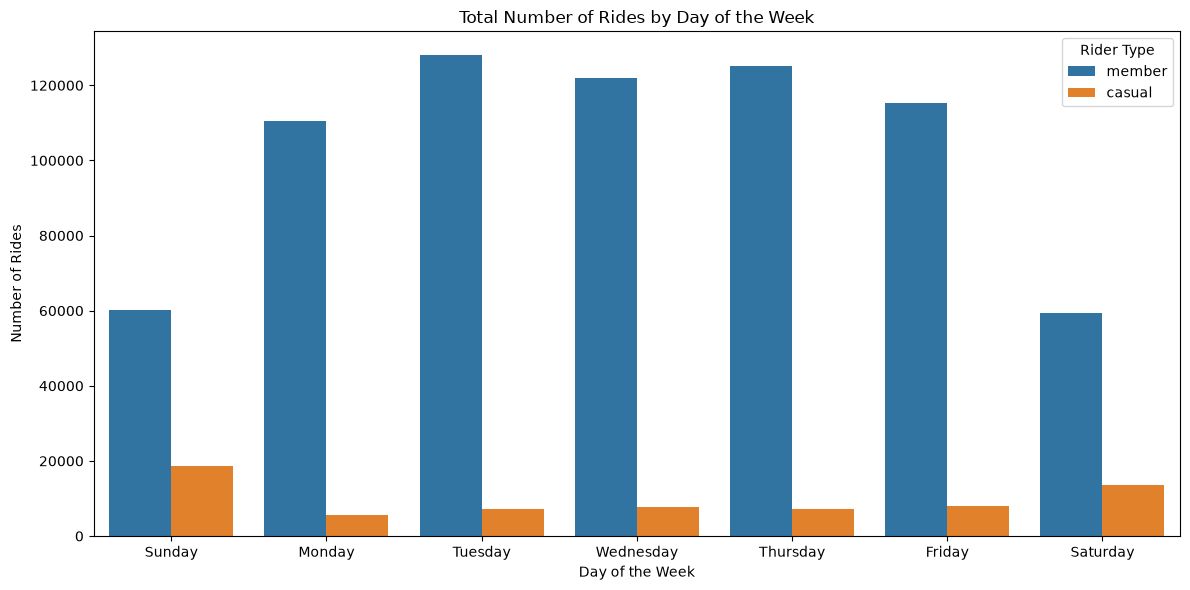

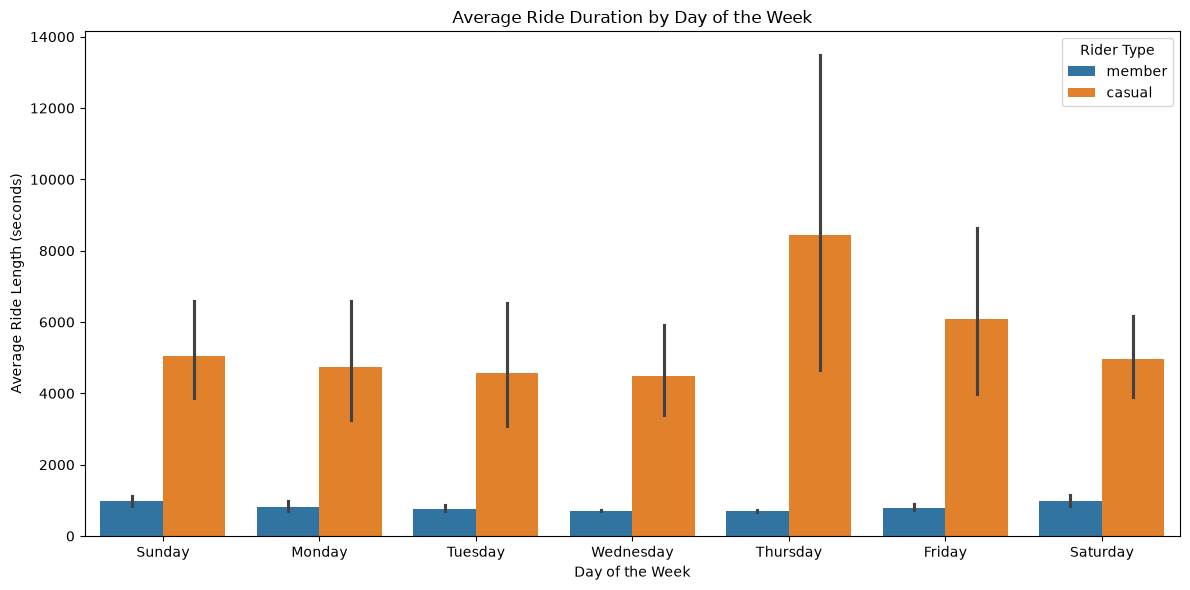

In [24]:


import matplotlib.pyplot as plt
import seaborn as sns

# Ensuring days of the week are ordered correctly
days_order = ["Sunday", "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday"]
all_trips_v2['day_of_week'] = pd.Categorical(all_trips_v2['day_of_week'], categories=days_order, ordered=True)

# 1. Total Number of Rides by Day and Rider Type
plt.figure(figsize=(12, 6))
sns.countplot(x='day_of_week', hue='member_casual', data=all_trips_v2)
plt.title('Total Number of Rides by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Number of Rides')
plt.legend(title='Rider Type')
plt.tight_layout()
plt.show()

# 2. Average Ride Duration by Day and Rider Type
plt.figure(figsize=(12, 6))
sns.barplot(x='day_of_week', y='ride_length', hue='member_casual', data=all_trips_v2, estimator=lambda x: sum(x) / len(x))
plt.title('Average Ride Duration by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Average Ride Length (seconds)')
plt.legend(title='Rider Type')
plt.tight_layout()
plt.show()